# YOLO26 inference: boxes, IoU, NMS and the NMS-free head

A robot that wants to pick up a mug first has to answer "what is where?" in every camera frame.
An **object detector** answers that with a set of axis-aligned boxes, each with a class label and a
confidence score. This notebook opens up a modern real-time detector, **Ultralytics YOLO26**
(the newest released YOLO family at the time of writing; YOLO27 was announced but has no
weights yet, so the model name is a variable you can swap later).

In this notebook we:

1. build intuition for **Intersection-over-Union (IoU)**, the overlap measure behind matching, NMS and mAP,
2. run YOLO26n and YOLO26s on COCO8 images and on frames from a **TUM RGB-D desk sequence** (a hand-held robot-eye view),
3. look at the **raw output tensor** of the classic *one-to-many* head (8400 candidate boxes),
4. implement **greedy non-maximum suppression (NMS)** from scratch and check it against `torchvision`,
5. compare with YOLO26's **one-to-one (NMS-free) head**, which outputs the final boxes directly,
6. measure **latency and peak VRAM** for n/s, fp32/fp16 and both heads on an RTX 5060 Laptop GPU.

**What you'll learn:** box formats, IoU and why it punishes small objects, anchor-free dense
prediction, why NMS exists and what an end-to-end head changes, and how to time GPU code properly.

**Prerequisites:** Python/NumPy/PyTorch basics. Data and weights: `make data-03_object_detection`
(YOLO26n/s checkpoints, COCO8 and the TUM fr1_desk sequence are fetched into `weights/` and `data/`).

## Setup

Imports, seeding and the device summary, repository-relative paths and the shared plot style.
`YOLO_AUTOINSTALL=false` must be set **before** importing `ultralytics`: otherwise the library may
`pip install` missing extras at runtime, bypassing this repository's constraints file. The
Ultralytics logger is set to errors only (its messages also contain absolute paths).

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# The YOLO model names are variables so a newer family (e.g. "yolo27n.pt") is a one-line swap.
import os

os.environ["YOLO_AUTOINSTALL"] = "false"
import gc
import io
import logging
import sys
from copy import deepcopy

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import ultralytics
from IPython.display import Image, display
from ultralytics import YOLO
from ultralytics.utils import LOGGER
from ultralytics.utils.torch_utils import get_flops, get_num_params

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.metrics import box_iou
from cvlab.tum import load_sequence

LOGGER.setLevel(logging.ERROR)
device = cvdevice.setup(seed=0)
viz.set_style()

PROJECT = "03_object_detection"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))  # project helpers (NMS, mAP evaluator, label I/O)
import detlib

MODEL_NAMES = ["yolo26n.pt", "yolo26s.pt"]  # resolved from weights/ultralytics/
COCO8_VAL = cvio.data_dir("ultralytics", "coco8", "images", "val")
TUM_DESK = cvio.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk")
for p in [cvio.weights_dir("ultralytics", m) for m in MODEL_NAMES] + [COCO8_VAL, TUM_DESK]:
    print(f"{p.relative_to(ROOT)}: {'ok' if p.exists() else 'MISSING - run make data-03_object_detection'}")
print("ultralytics", ultralytics.__version__)


def show_jpeg(fig, quality=85):
    # Photo-heavy figures are embedded as JPEG to keep the committed notebook small.
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=100, pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue()))


def bgr(img):
    # Ultralytics treats numpy inputs as OpenCV-style BGR; our images are RGB.
    return np.ascontiguousarray(img[..., ::-1])

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
weights/ultralytics/yolo26n.pt: ok
weights/ultralytics/yolo26s.pt: ok
data/ultralytics/coco8/images/val: ok
data/tum/fr1_desk/rgbd_dataset_freiburg1_desk: ok
ultralytics 8.4.204


## 1. Boxes and Intersection-over-Union

A detection is a tuple $(\mathbf{b}, c, s)$: a box $\mathbf{b}$, a class $c$ and a confidence $s \in [0, 1]$.
Boxes come in several conventions, and mixing them up is the most common detection bug:

| format | values | used by |
|---|---|---|
| `xyxy` | $(x_1, y_1, x_2, y_2)$ corners in pixels | NMS, metrics, drawing |
| `xywh` | $(c_x, c_y, w, h)$ centre + size in pixels | YOLO one-to-many head output |
| `xywhn` | `xywh` divided by image width/height | YOLO label files |

The overlap of a prediction $A$ and a ground-truth box $B$ is measured by

$$\mathrm{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|} \in [0, 1].$$

IoU is **scale invariant**: the same *relative* misalignment gives the same IoU at any size. The flip
side is that a fixed *pixel* error, e.g. 4 px of jitter, is negligible for a 200 px box but
catastrophic for a 16 px box. Far-away objects in a robot's camera are small, so they are much
harder to localise at a strict IoU threshold. The right-hand plot below quantifies this.

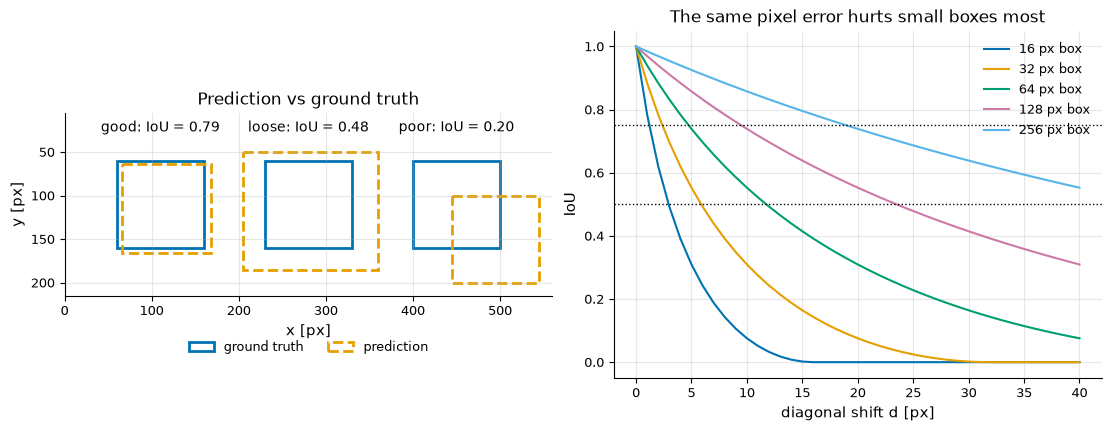

In [2]:
# --- IoU intuition: example pairs and IoU vs pixel shift for different box sizes ---
# Left: three prediction/ground-truth pairs. Right: IoU of a box with a copy of itself shifted
# diagonally by d pixels, for several box sizes (cvlab.metrics.box_iou expects xyxy boxes).
gt = np.array([60, 60, 160, 160], float)
pairs = {"good": gt + [6, 4, 8, 6], "loose": gt + [-25, -10, 30, 25], "poor": gt + [45, 40, 45, 40]}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
ax = axes[0]
for k, (name, pred) in enumerate(pairs.items()):
    off = np.array([k * 170, 0, k * 170, 0])
    for b, ls, lab in [(gt + off, "-", "ground truth"), (pred + off, "--", "prediction")]:
        ax.add_patch(plt.Rectangle(b[:2], *(b[2:] - b[:2]), fill=False, ls=ls, lw=2,
                                   color=viz.color(0 if ls == "-" else 1, unit=True),
                                   label=lab if k == 0 else None))
    iou = box_iou(gt[None], pred[None])[0, 0]
    ax.text(110 + k * 170, 22, f"{name}: IoU = {iou:.2f}", ha="center", va="center")
ax.set_xlim(0, 560), ax.set_ylim(215, 5), ax.set_aspect("equal")
ax.set_xlabel("x [px]"), ax.set_ylabel("y [px]"), ax.set_title("Prediction vs ground truth")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
shifts = np.arange(0, 41)
for size in [16, 32, 64, 128, 256]:
    b = np.array([[0, 0, size, size]], float)
    ious = [box_iou(b, b + [d, d, d, d])[0, 0] for d in shifts]
    axes[1].plot(shifts, ious, label=f"{size} px box")
for thr in (0.5, 0.75):
    axes[1].axhline(thr, color="k", ls=":", lw=1)
axes[1].set_xlabel("diagonal shift d [px]"), axes[1].set_ylabel("IoU")
axes[1].set_title("The same pixel error hurts small boxes most"), axes[1].legend()
viz.savefig(fig, PROJECT, "iou_intuition")
plt.show()

## 2. Load YOLO26n and YOLO26s

YOLO26 is an **anchor-free, single-stage** detector: a CNN backbone and neck produce feature maps
at strides 8, 16 and 32 px, and a small head predicts, *for every feature-map cell*, the distances
from the cell centre to the four box sides plus one sigmoid score per class. Compared with YOLO11,
YOLO26 removes Distribution Focal Loss (`reg_max = 1`: each side is one number, which simplifies
export to edge runtimes) and trains **two heads** side by side:

* a **one-to-many** head (`cv2`/`cv3`): many cells are trained as positives for each object, so at
  test time several neighbouring cells fire for the same object and NMS is required;
* a **one-to-one** head (`one2one_cv2`/`one2one_cv3`): exactly one cell is the positive for each
  object, so the network itself learns to suppress duplicates and NMS is unnecessary.

Both heads share the backbone; fusing for deployment drops the head that is not used.

In [3]:
# --- Load both models and summarise size, compute and head layout ---
# get_flops runs a 640x640 dummy forward; numbers are for the unfused model with both heads.
models = {name: YOLO(name) for name in MODEL_NAMES}
rows = []
for name, m in models.items():
    head = m.model.model[-1]
    rows.append({
        "model": name.removesuffix(".pt"),
        "params [M]": get_num_params(m.model) / 1e6,
        "GFLOPs @640": get_flops(m.model, 640),
        "classes": head.nc,
        "strides": head.stride.int().tolist(),
        "reg_max": head.reg_max,
        "has one-to-one head": getattr(head, "one2one_cv2", None) is not None,
    })
model_info = pd.DataFrame(rows).set_index("model")
model_info.round(2)

,params [M],GFLOPs @640,classes,strides,reg_max,has one-to-one head
model,,,,,,
yolo26n,2.57,6.24,80,"[8, 16, 32]",1,True
yolo26s,10.01,23.08,80,"[8, 16, 32]",1,True


## 3. Run the detector

`model.predict` handles everything: letterbox resize to 640 px, normalisation, the forward pass,
post-processing and rescaling the boxes back to the original image. `conf=0.25` is the default
display threshold. We run YOLO26s on the four COCO8 validation images and on two frames from the
**TUM RGB-D fr1_desk** sequence, a hand-held Kinect sweeping over an office desk, close to what a
mobile manipulator's head camera sees.

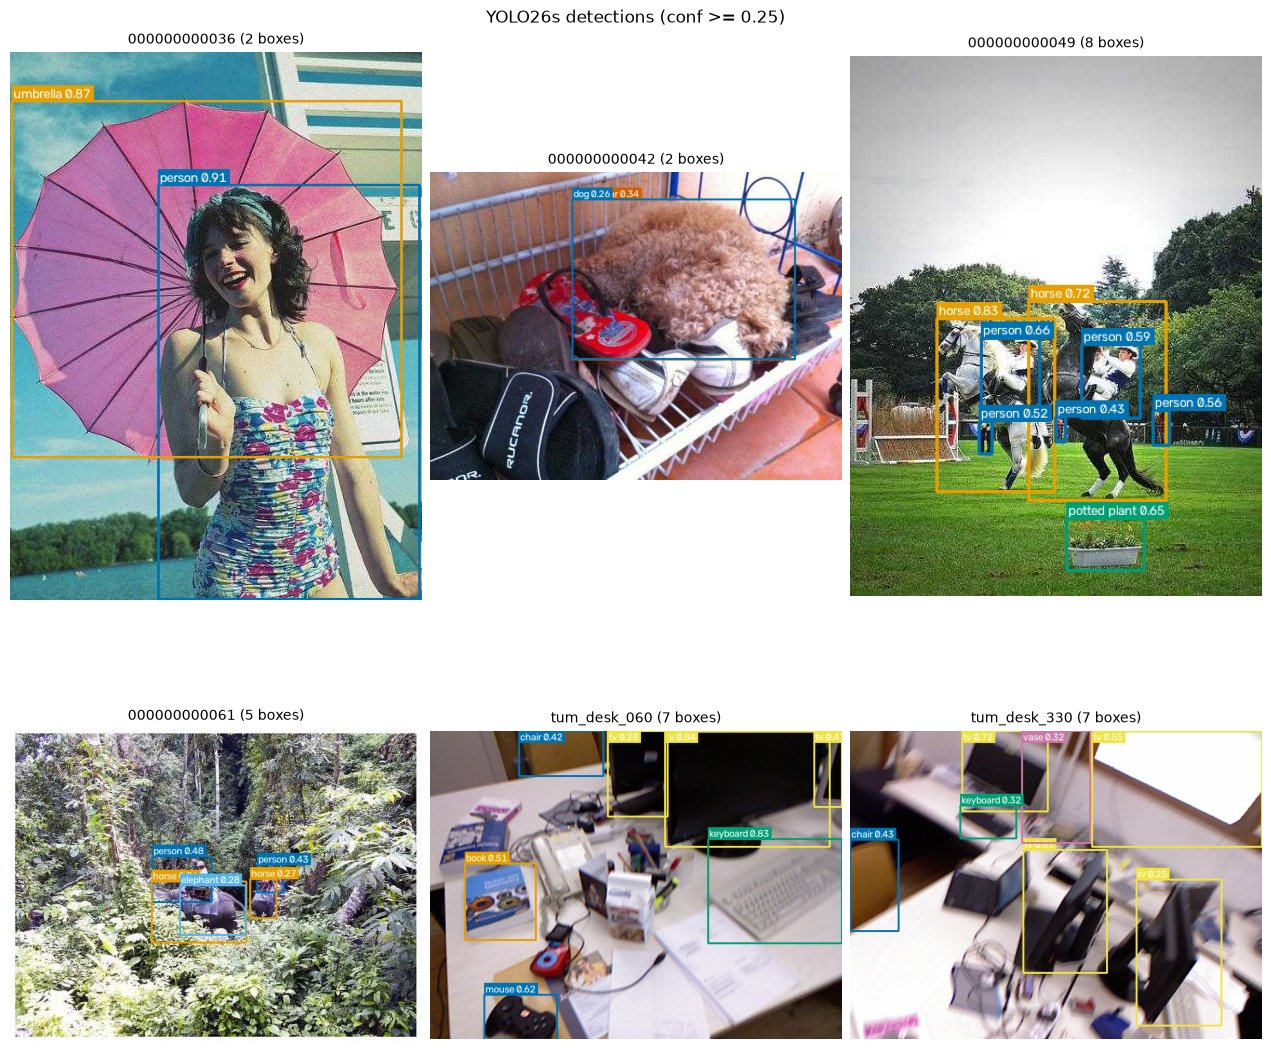

image
000000000036                                     person, umbrella
000000000042                                      dog, teddy bear
000000000049    horse, horse, person, person, person, person, ...
000000000061               elephant, horse, horse, person, person
tum_desk_060             book, chair, keyboard, mouse, tv, tv, tv
tum_desk_330                chair, keyboard, tv, tv, tv, tv, vase
Name: class, dtype: str

In [4]:
# --- Predict on COCO8 val images and two TUM desk frames ---
# Images are RGB uint8 numpy arrays; bgr() flips them for Ultralytics' OpenCV-style input.
seq = load_sequence(TUM_DESK)
images = {p.stem: cvio.read_image(p) for p in sorted(COCO8_VAL.glob("*.jpg"))}
for i in (60, 330):
    images[f"tum_desk_{i:03d}"] = seq.rgb(i)
model_s = models["yolo26s.pt"]
results = {k: model_s.predict(bgr(img), conf=0.25, verbose=False)[0] for k, img in images.items()}
panels, titles, det_rows = [], [], []
for k, r in results.items():
    d = detlib.ultralytics_to_detections(r)
    names = [r.names[c] for c in d.classes]
    panels.append(viz.draw_boxes(images[k], d.boxes, names, d.scores, d.classes))
    titles.append(f"{k} ({len(d.boxes)} boxes)")
    det_rows += [{"image": k, "class": n, "conf": s} for n, s in zip(names, d.scores)]
fig = viz.show_images(panels, titles, ncols=3, size=4.2, suptitle="YOLO26s detections (conf >= 0.25)")
show_jpeg(fig)
pd.DataFrame(det_rows).groupby("image")["class"].agg(lambda s: ", ".join(sorted(s)))

## 4. Under the hood: the raw one-to-many output

To see what NMS has to clean up, we run the network ourselves. First we **letterbox** the image:
scale it by $r = 640 / \max(H, W)$ and pad to $640 \times 640$ with grey (114), so the aspect ratio is
preserved. A box predicted in letterboxed pixels maps back to the original image by
$x = (x' - p_x)/r$, $y = (y' - p_y)/r$, where $(p_x, p_y)$ is the padding offset.

At 640 px the three feature maps have $80^2 + 40^2 + 20^2 = 8400$ cells. The one-to-many head
returns a tensor of shape $(B, 4 + 80, 8400)$: a `xywh` box and 80 class probabilities per cell.

In [5]:
# --- Letterbox one TUM frame and run the raw network with the one-to-many head ---
# net(x) returns (decoded predictions, raw head dict) in eval mode; we keep the decoded tensor.
def letterbox(img, size=640, fill=114):
    # Resize keeping aspect ratio, pad to size x size; returns (padded image, scale, (pad_x, pad_y)).
    h, w = img.shape[:2]
    r = size / max(h, w)
    nh, nw = round(h * r), round(w * r)
    out = np.full((size, size, 3), fill, np.uint8)
    px, py = (size - nw) // 2, (size - nh) // 2
    out[py:py + nh, px:px + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    return out, r, (px, py)


def to_tensor(img_lb, dtype=torch.float32):
    # HxWx3 uint8 RGB -> 1x3xHxW float in [0, 1] on the GPU.
    return torch.from_numpy(img_lb).permute(2, 0, 1)[None].to(device, dtype) / 255.0


def unletterbox(boxes, r, pad):
    # Letterboxed xyxy pixels -> original-image xyxy pixels.
    b = np.asarray(boxes, float).copy()
    b[:, [0, 2]] -= pad[0]
    b[:, [1, 3]] -= pad[1]
    return b / r


demo_key = "tum_desk_060"
img = images[demo_key]
img_lb, r, pad = letterbox(img)
x = to_tensor(img_lb)
net = deepcopy(model_s.model).to(device).eval()  # unfused copy that still has both heads
head = net.model[-1]
with torch.inference_mode():
    head.end2end = False
    y_many = net(x)[0]  # (1, 84, 8400): xywh + 80 class probabilities
    head.end2end = True
    y_one = net(x)[0]  # (1, 300, 6): x1 y1 x2 y2 score class (top-300, already ranked)
print("one-to-many output:", tuple(y_many.shape), "| one-to-one output:", tuple(y_one.shape))
scores_all = y_many[0, 4:].T  # (8400, 80)
best_score, best_cls = scores_all.max(1)
for thr in (0.05, 0.25, 0.5):
    print(f"cells with max class score > {thr}: {(best_score > thr).sum().item():5d} / {best_score.numel()}")

one-to-many output: (1, 84, 8400) | one-to-one output: (1, 300, 6)
cells with max class score > 0.05:   131 / 8400
cells with max class score > 0.25:    43 / 8400
cells with max class score > 0.5:    27 / 8400


## 5. Non-maximum suppression from scratch

Neighbouring cells all see the same object, so the one-to-many head fires several times per
object. **Greedy NMS** keeps the most confident box and deletes every remaining box of the same
class that overlaps it by more than a threshold $\tau$ (Ultralytics uses $\tau = 0.7$), then repeats:

```
sort candidates by score
while candidates remain:
    keep the top one, remove every remaining box with IoU(top, box) > tau
```

It is a hand-written heuristic with sharp failure modes: in crowds, two *different* people that
overlap by more than $\tau$ get merged (missed detection), and with a too-high $\tau$ duplicates
survive (false positives). It also costs $O(N^2)$ IoUs on the CPU/GPU after the network, which
is why it is often the latency bottleneck in deployment. `detlib.nms_numpy` implements the loop
above; class-aware NMS simply runs it per class.

In [6]:
# --- Greedy NMS: our NumPy version vs torchvision.ops.batched_nms vs Ultralytics ---
# Candidates: cells whose best class score exceeds conf=0.25; boxes converted xywh -> xyxy.
CONF, IOU = 0.25, 0.7
keep = best_score > CONF
xywh = y_many[0, :4].T[keep]
cand_boxes = torchvision.ops.box_convert(xywh, "cxcywh", "xyxy").cpu().numpy()
cand_scores, cand_cls = best_score[keep].cpu().numpy(), best_cls[keep].cpu().numpy()
ours = np.concatenate([np.flatnonzero(cand_cls == c)[detlib.nms_numpy(cand_boxes[cand_cls == c],
                                                                      cand_scores[cand_cls == c], IOU)]
                       for c in np.unique(cand_cls)])
ref = torchvision.ops.batched_nms(torch.tensor(cand_boxes), torch.tensor(cand_scores),
                                  torch.tensor(cand_cls), IOU).numpy()
print(f"{len(cand_boxes)} candidates -> {len(ours)} after our NMS, {len(ref)} after torchvision")
print("same set of kept boxes:", set(ours.tolist()) == set(ref.tolist()))
nms_boxes = unletterbox(cand_boxes[ours], r, pad)
nms_scores, nms_cls = cand_scores[ours], cand_cls[ours]
ul = detlib.ultralytics_to_detections(model_s.predict(bgr(img), conf=CONF, verbose=False)[0])
match = box_iou(nms_boxes, ul.boxes).max(1) if len(ul.boxes) else np.zeros(len(nms_boxes))
print(f"Ultralytics predict(): {len(ul.boxes)} boxes; median IoU of ours to theirs = {np.median(match):.3f}")

43 candidates -> 8 after our NMS, 8 after torchvision
same set of kept boxes: True
Ultralytics predict(): 7 boxes; median IoU of ours to theirs = 0.960


## 6. The one-to-one head: detection without NMS

The one-to-one head is trained with a **one-to-one label assignment**: for every ground-truth object
only the single best-matching cell is a positive, every other cell (including its neighbours) is
a negative. To minimise that loss the network has to learn *inside its weights* that only one
cell may fire per object. At inference the head simply returns the top-$k$ ($k=300$) scores, and a
confidence threshold is all the post-processing left. This idea comes from DETR-style set
prediction and YOLOv10's consistent dual assignment; YOLO26 keeps the one-to-many head as an
auxiliary training signal and as an optional inference path.

Below: the raw candidates (left), NMS on the one-to-many head (middle) and the one-to-one head
with only a confidence threshold (right). The **duplicate score** is the largest IoU between two
kept boxes of the same class: near 1 means duplicates, low values mean clean output.

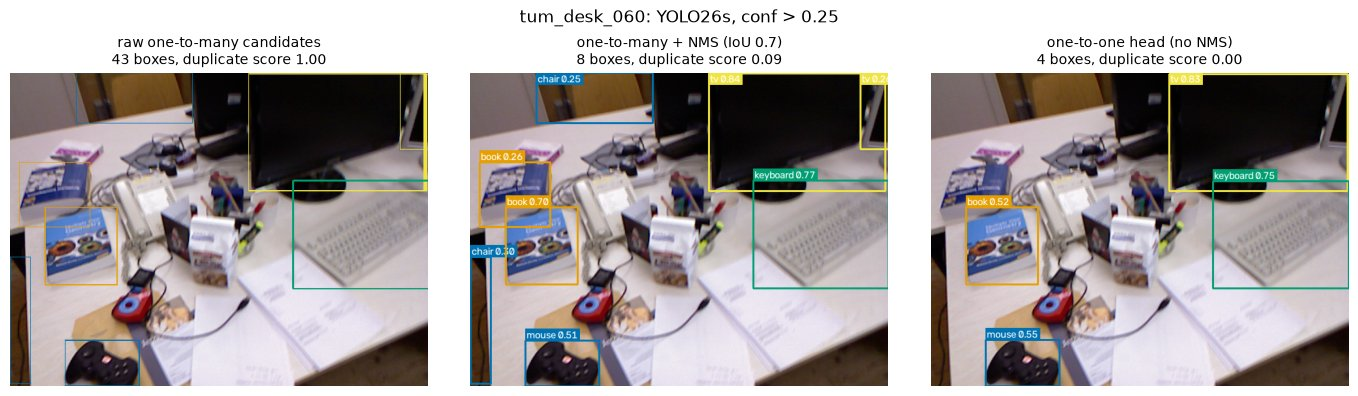

one-to-one boxes matched to an NMS box with IoU > 0.9: 4 / 4


,boxes,duplicate score
variant,,
raw one-to-many candidates,43,0.999
one-to-many + NMS (IoU 0.7),8,0.092
one-to-one head (no NMS),4,0.000


In [7]:
# --- Compare raw candidates, one-to-many + NMS and the NMS-free one-to-one head ---
# The one-to-one output is already xyxy in letterboxed pixels; we only threshold the scores.
one = y_one[0].cpu().numpy()
one = one[one[:, 4] > CONF]
e2e_boxes, e2e_scores, e2e_cls = unletterbox(one[:, :4], r, pad), one[:, 4], one[:, 5].astype(int)


def duplicate_score(boxes, cls):
    # Max IoU between two boxes of the same class (0 if no class has two boxes).
    worst = 0.0
    for c in np.unique(cls):
        b = boxes[cls == c]
        if len(b) > 1:
            iou = box_iou(b, b)
            np.fill_diagonal(iou, 0)
            worst = max(worst, iou.max())
    return worst


raw_boxes = unletterbox(cand_boxes, r, pad)
variants = {
    "raw one-to-many candidates": (raw_boxes, cand_scores, cand_cls),
    f"one-to-many + NMS (IoU {IOU})": (nms_boxes, nms_scores, nms_cls),
    "one-to-one head (no NMS)": (e2e_boxes, e2e_scores, e2e_cls),
}
panels, titles, dup_rows = [], [], []
for title, (b, s, c) in variants.items():
    labels = [model_s.names[int(k)] for k in c] if len(b) < 40 else None
    panels.append(viz.draw_boxes(img, b, labels, s if labels else None, c, thickness=1 if labels is None else 2))
    dup = duplicate_score(b, c)
    titles.append(f"{title}\n{len(b)} boxes, duplicate score {dup:.2f}")
    dup_rows.append({"variant": title, "boxes": len(b), "duplicate score": dup})
fig = viz.show_images(panels, titles, ncols=3, size=4.6, suptitle=f"{demo_key}: YOLO26s, conf > {CONF}")
viz.savefig(fig, PROJECT, "nms_vs_one2one")
show_jpeg(fig)
iou_e2e_vs_nms = box_iou(e2e_boxes, nms_boxes).max(1) if len(nms_boxes) else np.zeros(0)
print("one-to-one boxes matched to an NMS box with IoU > 0.9:", int((iou_e2e_vs_nms > 0.9).sum()), "/", len(e2e_boxes))
pd.DataFrame(dup_rows).set_index("variant").round(3)

## 7. Thresholds: what the operating point changes

Detectors output scores, not decisions: the **confidence threshold** trades missed objects
against false alarms, and for NMS the **IoU threshold** $\tau$ trades duplicates against merged
neighbours. We sweep both over all six images. For the one-to-one head only the confidence
threshold exists.

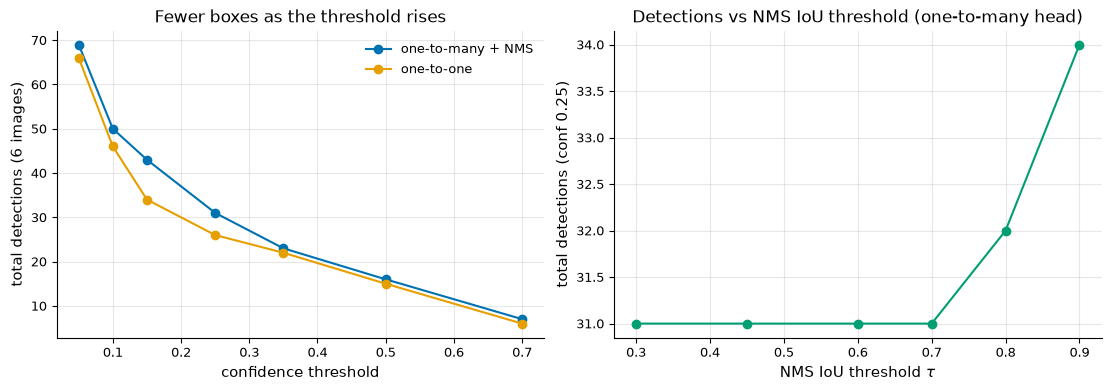

In [8]:
# --- Sweep the confidence threshold (both heads) and the NMS IoU threshold ---
# predict(nms=False) selects the one-to-one head; nms=None (default) = one-to-many + NMS. nms is passed
# explicitly every time: Ultralytics only rebuilds its cached predictor when a setup argument changes.
confs = [0.05, 0.1, 0.15, 0.25, 0.35, 0.5, 0.7]
sweep = []
for conf in confs:
    for head_name, nms_arg in [("one-to-many + NMS", None), ("one-to-one", False)]:
        n = sum(len(model_s.predict(bgr(im), conf=conf, nms=nms_arg, verbose=False)[0].boxes)
                for im in images.values())
        sweep.append({"conf": conf, "head": head_name, "detections": n})
sweep = pd.DataFrame(sweep)
iou_thrs = [0.3, 0.45, 0.6, 0.7, 0.8, 0.9]
n_vs_iou = [sum(len(model_s.predict(bgr(im), conf=0.25, iou=t, nms=None, verbose=False)[0].boxes)
                for im in images.values()) for t in iou_thrs]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for k, (h, g) in enumerate(sweep.groupby("head")):
    axes[0].plot(g["conf"], g["detections"], "o-", label=h, color=viz.color(k, unit=True))
axes[0].set_xlabel("confidence threshold"), axes[0].set_ylabel("total detections (6 images)")
axes[0].set_title("Fewer boxes as the threshold rises"), axes[0].legend()
axes[1].plot(iou_thrs, n_vs_iou, "o-", color=viz.color(2, unit=True))
axes[1].set_xlabel("NMS IoU threshold $\\tau$"), axes[1].set_ylabel("total detections (conf 0.25)")
axes[1].set_title("Detections vs NMS IoU threshold (one-to-many head)")
plt.show()

## 8. Latency and memory

GPU kernels run **asynchronously**: `model(x)` returns as soon as the work is queued, so a naive
`time.time()` measures almost nothing. `cvlab.bench.benchmark` calls `torch.cuda.synchronize()`
around every iteration and discards warm-up runs (cuDNN autotuning, memory pool growth).

Two more pitfalls matter on a laptop shared with other jobs: the GPU changes its clocks
dynamically, and at batch 1 these small networks are bound by the **CPU launching kernels**, so any
other CPU load shows up as latency noise. We therefore build all configurations first, then time
them **interleaved over 5 rounds** and report the median of the per-round medians (with the
min-max over rounds as error bars).

Configurations: the **fused** network (Conv+BN folded, unused head dropped) for every combination
of model size, precision and head, plus the post-processing each head needs (score threshold +
`torchvision` batched NMS on the GPU vs a plain threshold), at batch 1 and 640x640 input. Peak VRAM
is `torch.cuda.max_memory_allocated()` while building and running one configuration minus what was
allocated before, i.e. that configuration's weights + activations (the CUDA context and cuDNN
workspaces outside PyTorch's allocator are not included).

In [9]:
# --- Build the 8 fused configurations and record each one's peak VRAM ---
# gc.collect() + empty_cache() first, so memory freed by earlier objects does not distort the baseline.
def fused(model, end2end, half):
    net = deepcopy(model.model).to(device).eval()
    net.model[-1].end2end = end2end
    net.fuse(verbose=False)
    return net.half() if half else net


def post_nms(y, conf=0.25, iou=0.7):
    # One-to-many decode: best class per cell, threshold, xywh->xyxy, class-aware NMS on the GPU.
    y = y[0].float()
    s, c = y[4:].max(0)
    k = s > conf
    b = torchvision.ops.box_convert(y[:4, k].T, "cxcywh", "xyxy")
    return torchvision.ops.batched_nms(b, s[k], c[k], iou)


def post_e2e(y, conf=0.25):
    # One-to-one: the head already ranked the top-300 boxes; only a threshold is left.
    return y[0][y[0, :, 4] > conf]


x_bench = to_tensor(img_lb)
configs = []
for name, m in models.items():
    for half in (False, True):
        for e2e in (False, True):
            gc.collect()
            torch.cuda.empty_cache()
            torch.cuda.synchronize()
            base = torch.cuda.memory_allocated()
            torch.cuda.reset_peak_memory_stats()
            net = fused(m, e2e, half)
            xb = x_bench.half() if half else x_bench
            post = post_e2e if e2e else post_nms
            with torch.inference_mode():
                post(net(xb)[0])
            torch.cuda.synchronize()
            configs.append({"model": name.removesuffix(".pt"), "precision": "fp16" if half else "fp32",
                            "head": "one-to-one" if e2e else "one-to-many + NMS", "net": net, "x": xb,
                            "post": post, "peak VRAM [MiB]": (torch.cuda.max_memory_allocated() - base) / 2**20})
print(f"{len(configs)} configurations built")

8 configurations built


Now the interleaved timing. Each round runs every configuration once (50 timed forward passes and
50 timed post-processing calls after a short warm-up); round 0 is an extra discarded warm-up.

In [10]:
# --- Interleaved timing: 1 warm-up round + 5 measured rounds over all configurations ---
# p50 per round, then the median (and min/max) across rounds.
ROUNDS = 5
fwd_ms = np.zeros((ROUNDS, len(configs)))
post_ms = np.zeros((ROUNDS, len(configs)))
with torch.inference_mode():
    for rnd in range(-1, ROUNDS):
        for i, c in enumerate(configs):
            f = benchmark(c["net"], c["x"], warmup=10, iters=50)
            y = c["net"](c["x"])[0]
            p = benchmark(c["post"], y, warmup=5, iters=50)
            if rnd >= 0:
                fwd_ms[rnd, i], post_ms[rnd, i] = f["p50_ms"], p["p50_ms"]
lat = pd.DataFrame([{k: c[k] for k in ("model", "precision", "head", "peak VRAM [MiB]")} for c in configs])
lat["forward [ms]"] = np.median(fwd_ms, 0)
lat["forward min [ms]"], lat["forward max [ms]"] = fwd_ms.min(0), fwd_ms.max(0)
lat["post [ms]"] = np.median(post_ms, 0)
lat["total [ms]"] = lat["forward [ms]"] + lat["post [ms]"]
lat["FPS"] = 1000 / lat["total [ms]"]
lat.round(2)

,model,precision,head,peak VRAM [MiB],forward [ms],forward min [ms],forward max [ms],post [ms],total [ms],FPS
0,yolo26n,fp32,one-to-many + NMS,11.14,2.85,2.79,3.12,0.24,3.09,323.86
1,yolo26n,fp32,one-to-one,27.97,2.94,2.87,2.98,0.03,2.97,336.45
2,yolo26n,fp16,one-to-many + NMS,17.14,2.48,2.48,2.61,0.24,2.73,366.85
3,yolo26n,fp16,one-to-one,17.14,2.64,2.64,2.83,0.03,2.67,374.46
4,yolo26s,fp32,one-to-many + NMS,85.33,5.42,5.40,5.80,0.24,5.67,176.51
5,yolo26s,fp32,one-to-one,86.16,5.56,5.48,5.68,0.03,5.59,178.93
6,yolo26s,fp16,one-to-many + NMS,43.16,3.69,3.58,3.72,0.25,3.94,253.79
7,yolo26s,fp16,one-to-one,43.44,3.70,3.64,3.75,0.03,3.73,268.00


The network-level numbers above exclude the CPU work every real pipeline has. `predict()` reports
its own three stages (`results.speed`, in ms): letterbox + normalisation on the CPU, the forward
pass, and post-processing (NMS or the threshold, plus rescaling boxes to the original image).
We give each (model, head) pair its own `YOLO` instance (so the cached predictor is never rebuilt),
warm them up, and then run 30 TUM desk frames (640x480, rectangular letterbox) through all four
in 3 interleaved rounds, reporting medians per stage.

In [11]:
# --- End-to-end predict() latency on 30 TUM frames (both heads, both sizes, fp32) ---
# Separate YOLO instances per head; 3 warm-up calls each before the interleaved measurement.
HEADS = {"one-to-many + NMS": None, "one-to-one": False}
tum_frames = [bgr(seq.rgb(i)) for i in range(0, 300, 10)]
pipes = {(n, h): YOLO(n) for n in MODEL_NAMES for h in HEADS}
for (_, h), pm in pipes.items():
    for f in tum_frames[:3]:
        pm.predict(f, nms=HEADS[h], verbose=False)
speeds = {key: [] for key in pipes}
for _ in range(3):
    for (n, h), pm in pipes.items():
        speeds[(n, h)] += [pm.predict(f, nms=HEADS[h], verbose=False)[0].speed for f in tum_frames]
speed = pd.DataFrame([{"model": n.removesuffix(".pt"), "head": h,
                       **{f"{k} [ms]": v for k, v in pd.DataFrame(speeds[(n, h)]).median().items()}}
                      for (n, h) in pipes])
speed["total [ms]"] = speed[["preprocess [ms]", "inference [ms]", "postprocess [ms]"]].sum(axis=1)
speed.round(2)

,model,head,preprocess [ms],inference [ms],postprocess [ms],total [ms]
0,yolo26n,one-to-many + NMS,0.20,2.64,0.39,3.23
1,yolo26n,one-to-one,0.19,2.63,0.14,2.96
2,yolo26s,one-to-many + NMS,0.20,4.28,0.40,4.88
3,yolo26s,one-to-one,0.20,4.28,0.14,4.62


## Results

The latency chart stacks forward-pass and post-processing time per configuration (batch 1,
640x640, RTX 5060 Laptop GPU); peak VRAM is shown alongside. The thumbnail used in the repository
README is saved here as well.

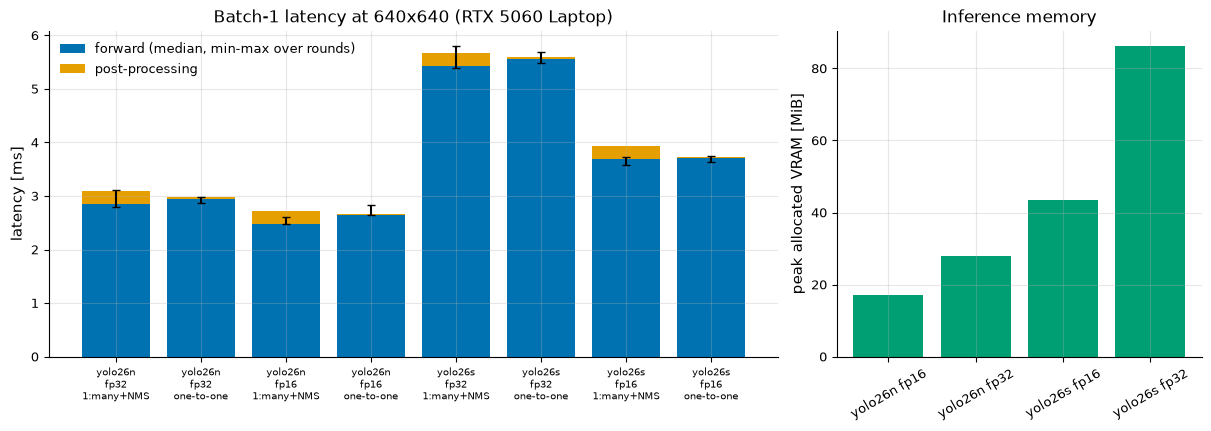

In [12]:
# --- Results figure: latency breakdown and peak VRAM per configuration ---
# Bars are stacked forward + post-processing medians over the 5 interleaved rounds.
lat["config"] = lat["model"] + "\n" + lat["precision"] + "\n" + lat["head"].str.replace("one-to-many + NMS", "1:many+NMS")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, width_ratios=[2, 1])
xs = np.arange(len(lat))
err = [lat["forward [ms]"] - lat["forward min [ms]"], lat["forward max [ms]"] - lat["forward [ms]"]]
axes[0].bar(xs, lat["forward [ms]"], yerr=err, capsize=3, color=viz.color(0, unit=True), label="forward (median, min-max over rounds)")
axes[0].bar(xs, lat["post [ms]"], bottom=lat["forward [ms]"], color=viz.color(1, unit=True), label="post-processing")
axes[0].set_xticks(xs, lat["config"], fontsize=7)
axes[0].set_ylabel("latency [ms]"), axes[0].set_title("Batch-1 latency at 640x640 (RTX 5060 Laptop)")
axes[0].legend()
vram = lat.groupby(["model", "precision"])["peak VRAM [MiB]"].max().reset_index()
axes[1].bar(vram["model"] + " " + vram["precision"], vram["peak VRAM [MiB]"], color=viz.color(2, unit=True))
axes[1].set_ylabel("peak allocated VRAM [MiB]"), axes[1].set_title("Inference memory")
axes[1].tick_params(axis="x", rotation=30)
viz.savefig(fig, PROJECT, "latency_heads")
plt.show()

# Thumbnail for the root README: YOLO26s detections on a TUM desk frame (~400 px wide).
d = detlib.ultralytics_to_detections(results["tum_desk_060"])
thumb = viz.draw_boxes(images["tum_desk_060"], d.boxes, [model_s.names[c] for c in d.classes], d.scores, d.classes)
fig_t, ax_t = plt.subplots(figsize=(3.4, 2.6), constrained_layout=True)
ax_t.imshow(thumb), ax_t.axis("off")
viz.savefig(fig_t, PROJECT, "thumb")
plt.close(fig_t)

Summary table: one row per model / precision / head. "end-to-end predict" is the median total of
`predict()` (pre + inference + post) on 30 TUM frames x 3 rounds in fp32.

In [13]:
# --- Summary table of everything measured in this notebook ---
# Joins network-level timings with model size and the full predict() latency; also saved to results/.
summary = lat.drop(columns=["config", "forward min [ms]", "forward max [ms]"]).merge(
    speed[["model", "head", "total [ms]"]].rename(columns={"total [ms]": "end-to-end predict fp32 [ms]"}),
    on=["model", "head"])
summary.insert(1, "params [M]", summary["model"].map(model_info["params [M]"]))
summary.round(3).to_csv(PROJ_DIR / "results" / "nb01_latency.csv", index=False)
summary.round(2)

,model,params [M],precision,head,peak VRAM [MiB],forward [ms],post [ms],total [ms],FPS,end-to-end predict fp32 [ms]
0,yolo26n,2.57,fp32,one-to-many + NMS,11.14,2.85,0.24,3.09,323.86,3.23
1,yolo26n,2.57,fp32,one-to-one,27.97,2.94,0.03,2.97,336.45,2.96
2,yolo26n,2.57,fp16,one-to-many + NMS,17.14,2.48,0.24,2.73,366.85,3.23
3,yolo26n,2.57,fp16,one-to-one,17.14,2.64,0.03,2.67,374.46,2.96
4,yolo26s,10.01,fp32,one-to-many + NMS,85.33,5.42,0.24,5.67,176.51,4.88
5,yolo26s,10.01,fp32,one-to-one,86.16,5.56,0.03,5.59,178.93,4.62
6,yolo26s,10.01,fp16,one-to-many + NMS,43.16,3.69,0.25,3.94,253.79,4.88
7,yolo26s,10.01,fp16,one-to-one,43.44,3.70,0.03,3.73,268.00,4.62


### Takeaways

* **IoU is scale-free, pixel errors are not.** A 4 px shift costs a 16 px box far more IoU than a
  128 px box, which is why AP on small objects is always the weakest number and why high-IoU
  metrics (AP75, AP50-95) punish distant objects.
* **The one-to-many head floods the image.** On the TUM desk frame 43 cells clear a 0.25 score
  threshold (131 clear 0.05). Greedy NMS, a dozen lines of NumPy that keep exactly the same boxes as
  `torchvision.ops.batched_nms`, reduces them to 8. Ultralytics' own `predict()` returns 7 boxes
  (median IoU 0.96 to ours) because it letterboxes to a rectangular 640x480 input instead of our
  square 640x640, so the candidates differ slightly.
* **The NMS IoU threshold mattered little on these images:** any $\tau$ between 0.3 and 0.7 kept the
  same 31 boxes over the six images; only $\tau \ge 0.8$ let duplicates through (32 and 34 boxes).
* **YOLO26's one-to-one head suppresses duplicates inside the network** (duplicate score 0.00), and
  each of its 4 boxes on the desk frame has an NMS twin with IoU > 0.9. It is, however, more
  conservative: the low-confidence NMS boxes (a second chair, a book at 0.26, a partly visible
  monitor) score below 0.25 under the one-to-one head, and the threshold sweep shows fewer
  detections at every threshold (26 vs 31 at 0.25). The two heads' scores are calibrated
  differently, so a threshold tuned for one does not transfer to the other.
* **Latency is launch-bound at batch 1.** Fused YOLO26s is only 1.9x slower than YOLO26n in fp32
  (5.42 vs 2.85 ms forward, one-to-many head) although it needs 3.7x the FLOPs (23.1 vs 6.2
  GFLOPs). fp16 helps the larger model much more (YOLO26s 5.42 -> 3.69 ms, YOLO26n 2.85 -> 2.48 ms).
  GPU NMS adds about 0.25 ms versus 0.03 ms for the one-to-one threshold. The whole fp32 `predict()`
  call on a 640x480 TUM frame takes 2.96-3.23 ms (n) and 4.62-4.88 ms (s), depending on the head,
  with only about 0.2 ms of CPU pre-processing.
* **Memory is not the constraint:** every configuration allocates under 90 MiB for weights and
  activations (plus the CUDA context), leaving almost all of the 8 GB for other perception modules.

## Exercises

Solutions are in `projects/03_object_detection/solutions/`.

**Exercise 1 - class-agnostic NMS.** A desk often contains near-identical classes (`cup` vs `bowl`,
`laptop` vs `tv`). Run class-aware and class-agnostic NMS (`detlib.nms_numpy` on all candidates at
once) on the one-to-many candidates of every TUM frame used above and count how many cross-class
duplicates the agnostic version removes. When would you want each in a robot?

In [14]:
# --- Exercise 1: class-aware vs class-agnostic NMS ---
# TODO: for each image, decode one-to-many candidates (see section 5), run per-class NMS and
#       agnostic NMS, and report the number of boxes each keeps and which classes disappear.

**Exercise 2 - input resolution vs latency and small objects.** Predict on the TUM frames with
`imgsz` in {320, 480, 640, 960} using YOLO26n. Plot mean `predict()` latency and the number of
detections smaller than 32x32 px against `imgsz`.

In [15]:
# --- Exercise 2: imgsz sweep ---
# TODO: loop over imgsz values, call models["yolo26n.pt"].predict(frame, imgsz=s, verbose=False),
#       collect results.speed and the count of boxes with area < 32**2, then plot both vs imgsz.

**Exercise 3 - Soft-NMS.** Instead of deleting overlapping boxes, Gaussian Soft-NMS decays their
score: $s_i \leftarrow s_i \exp(-\mathrm{IoU}(M, b_i)^2/\sigma)$. Implement it and compare the number of
surviving boxes with hard NMS on the COCO8 image with the horses and people (`000000000049`).

In [16]:
# --- Exercise 3: Gaussian Soft-NMS ---
# TODO: implement soft_nms(boxes, scores, sigma=0.5, score_thr=0.25) in NumPy and compare it with
#       detlib.nms_numpy on the one-to-many candidates of images["000000000049"].